# 15 — Gauging the idle parameters on the H2 emulator

The regime question turns on how fast idle qubits dephase and how long a step of work takes. Guppy
has no delay instruction, so idle time is made with spectators: 8 target qubits wait while other
qubits do L layers of work, then the targets are read out. Targets in |+⟩ (X basis) feel Z
dephasing; targets in |0⟩ (Z basis) should not. A Z on the targets conditioned on the spectators'
outcomes (feed-forward) keeps their readout after the wait.

**Runs.** H2-1E via aqora (`q_sq`). Results: `results/hardware/h2_1e_calibration_runs.fit.json`,
`h2_1e_transport_idle.fit.json`, `h2_1e_anchored_idle.fit.json`, `h2_1e_anchored_idle_long*.json`.

In [1]:
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from qec_timing import plotting as P
P.style()
R = Path("..") / "results"

In [2]:
import math
from scipy.stats import beta
cp = lambda k, n: (beta.ppf(.025, k, n - k + 1) if k else 0.0, beta.ppf(.975, k + 1, n - k))
H = R / "hardware"
cal = json.loads((Path("..") / "config" / "h2_1e_emulator.json").read_text())
first = json.loads((H / "h2_1e_calibration_runs.fit.json").read_text())
ro = first["readout"]
print(f"readout (800 samples each): p_meas0 = {ro['p_meas0']:.4f}, p_meas1 = {ro['p_meas1']:.4f}  "
      f"(emulator model {cal['p_meas0']}, {cal['p_meas1']})")

readout (800 samples each): p_meas0 = 0.0025, p_meas1 = 0.0025  (emulator model 0.0006, 0.00139)


## Three spectator designs

1. **measure-and-reset:** 2 spectators do H, measure, reset per layer (forces no transport);
2. **transport:** 8 spectators do H and a native ZZ on a fresh random pairing per layer
   (Quantinuum's own memory-benchmark layer);
3. **anchored:** as 2, but each target is first tied to an anchor qubit (a ZZ, undone at the end)
   that also touches the spectators, so a scheduler cannot prepare the targets late.

Without the anchor nothing forces a target's H to happen before the wait: a scheduler can move it
to just before readout, the target then waits in |0⟩ and sees no dephasing.

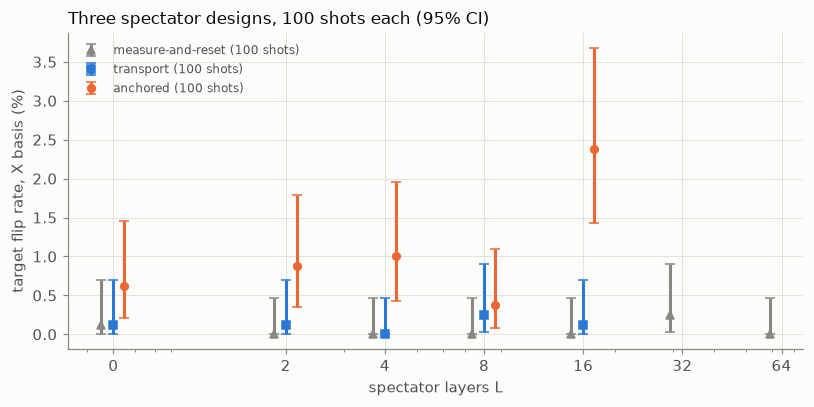

In [3]:
designs = [("measure-and-reset", first["idle"]["X"], 800, P.MUTED, "^"),
           ("transport", json.loads((H / "h2_1e_transport_idle.fit.json").read_text())["idle"]["X"], 800, P.SERIES[0], "s"),
           ("anchored", json.loads((H / "h2_1e_anchored_idle.fit.json").read_text())["idle"]["X"], 800, P.SERIES[1], "o")]
fig, ax = plt.subplots(figsize=(7.5, 3.8))
for i, (lab, d, n, col, mk) in enumerate(designs):
    L = np.array(d["layers"]); p = np.array(d["P"]); k = np.round(p * n).astype(int)
    ci = np.array([cp(int(v), n) for v in k]).T; x = np.where(L == 0, 0.6, L) * (0.92 + 0.08 * i)
    ax.errorbar(x, p * 100, yerr=[(p - ci[0]) * 100, (ci[1] - p) * 100], fmt=mk, color=col, capsize=3, label=f"{lab} (100 shots)")
ax.set_xscale("log"); ax.set_xticks([0.6, 2, 4, 8, 16, 32, 64], ["0", "2", "4", "8", "16", "32", "64"])
ax.xaxis.set_minor_formatter(plt.NullFormatter())
ax.set_xlabel("spectator layers L"); ax.set_ylabel("target flip rate, X basis (%)"); ax.legend(fontsize=8)
ax.set_title("Three spectator designs, 100 shots each (95% CI)", loc="left")
fig.tight_layout()
P.save(fig, "15_emulator_idle_parameters_1")

**Reading.**
- *Measured:* measure-and-reset and transport spectators give no growth up to L = 64 and 16. The
  anchored targets sit on a higher floor (two extra ZZ gates each). The single high point at
  L = 16 (2.4%) was not reproduced with 10× the shots below: a fluctuation.

## Anchored, long waits (1000 shots = 8000 samples per X point)

In [4]:
from scipy.stats import chi2 as chi2_dist
lg = json.loads((H / "h2_1e_anchored_idle_long.json").read_text())
om = 2 * math.pi * cal["quad_rate"] * cal["quad_factor"]; g = cal["gamma"]
pz = lambda t: g * t + np.sin(om * t / 2) ** 2 - 2 * g * t * np.sin(om * t / 2) ** 2
L = np.array([l for l in (0, 16, 32, 64, 128) if f"X_L{l}" in lg]); n = 8000
k = np.array([lg[f"X_L{l}"]["k"] for l in L]); p = k / n; se = np.sqrt(p * (1 - p) / n)
for l, kk in zip(L, k):
    print(f"X, L = {l:>3}: {kk}/{n} = {100 * kk / n:.2f}%")
print(f"Z, L =  64: {lg['Z_L64']['k']}/{lg['Z_L64']['n']} = {100 * lg['Z_L64']['p']:.2f}%")
w = 1 / se ** 2; m = (w * p).sum() / w.sum(); c = (((p - m) / se) ** 2).sum()
print(f"no growth (constant {100 * m:.2f}%): chi2 {c:.1f} on {len(L) - 1} dof, p = {chi2_dist.sf(c, len(L) - 1):.3f}")

X, L =   0: 82/8000 = 1.02%
X, L =  16: 93/8000 = 1.16%
X, L =  32: 112/8000 = 1.40%
X, L =  64: 120/8000 = 1.50%
X, L = 128: 89/8000 = 1.11%
Z, L =  64: 18/4000 = 0.45%
no growth (constant 1.22%): chi2 10.2 on 4 dof, p = 0.037


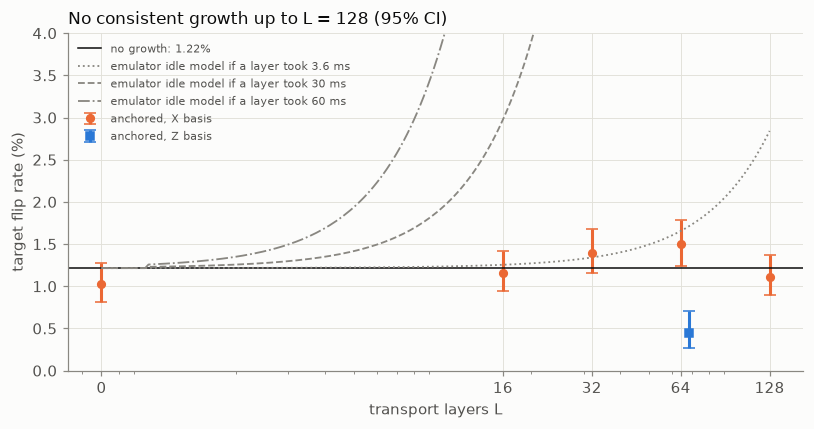

In [5]:
fig, ax = plt.subplots(figsize=(7.5, 4))
ci = np.array([cp(int(v), n) for v in k]).T; x = np.where(L == 0, 0.7, L)
ax.errorbar(x, p * 100, yerr=[(p - ci[0]) * 100, (ci[1] - p) * 100], fmt="o", color=P.SERIES[1], capsize=4, label="anchored, X basis")
z = lg["Z_L64"]; lo, hi = cp(z["k"], z["n"])
ax.errorbar([64 * 1.07], [100 * z["p"]], yerr=[[100 * (z["p"] - lo)], [100 * (hi - z["p"])]], fmt="s", color=P.SERIES[0], capsize=4, label="anchored, Z basis")
ax.axhline(100 * m, color=P.INK, lw=1, label=f"no growth: {100 * m:.2f}%")
Ls = np.geomspace(0.7, 128, 200)
for tt, ls in ((3.6e-3, ":"), (30e-3, "--"), (60e-3, "-.")):
    q = pz(tt * np.where(Ls < 1, 0, Ls)); ax.plot(Ls, (m + q - 2 * m * q) * 100, ls, color=P.MUTED, lw=1.2, label=f"emulator idle model if a layer took {tt * 1e3:g} ms")
ax.set_xscale("log"); ax.set_xticks([0.7, 16, 32, 64, 128], ["0", "16", "32", "64", "128"]); ax.xaxis.set_minor_formatter(plt.NullFormatter())
ax.set_ylim(0, 4); ax.set_xlabel("transport layers L"); ax.set_ylabel("target flip rate (%)"); ax.legend(fontsize=7.5, loc="upper left")
ax.set_title("No consistent growth up to L = 128 (95% CI)", loc="left")
fig.tight_layout()
P.save(fig, "15_emulator_idle_parameters_2")

**Reading.**
- *Measured:* the X-basis flip rate stays near 1.2% from L = 0 to 128 (1.03, 1.16, 1.40, 1.50,
  1.11%); the Z basis stays low (0.45%). The points scatter more than chance allows around a
  constant (p ≈ 0.04), but they do not rise steadily: L = 128 is back at the floor.
- *Measured:* any idle dephasing of the waiting targets is below ~0.5% even at L = 128. With the
  emulator's own idle rates that means under ~0.2 s of effective idling in 128 layers: ≲ 1–2 ms
  per layer, if the targets really idle in |+⟩ for the whole wait. The ~60 ms published depth-one
  time is ruled out for these layers.
- *Withdrawn:* an earlier 100-shot point (2.4% at L = 16) and a 4-point fit (≈ 3.6 ms per layer)
  were not confirmed by the L = 128 run.
- *Open:* whether the emulator applies its idle dephasing to these programs at all. Longer waits
  are capped: L = 256 (~1050 two-qubit gates) was refused as over the per-job cost limit. The
  time per layer depends on circuit size, so it does not give a surface-code round time.